# **Practical Assignment 5**

Name: Diya Rao

Batch: E1

Roll No: 322

PRN: 202401040343

### Ensemble Learning and Performance Evaluation

# **Python Implementation**
## Step 1: Import Required Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


## Step 2: Load and Prepare Dataset

In [2]:

# Load dataset
data = load_breast_cancer()

X = data.data

# 1 = Malignant, 0 = Benign
y = (data.target == 0).astype(int)

print("Dataset Shape:", X.shape)
print("Total Features:", X.shape[1])

print("\nClass Distribution:")
print(pd.Series(y).value_counts().rename(
    index={0: "Benign", 1: "Malignant"}
))

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Dataset Shape: (569, 30)
Total Features: 30

Class Distribution:
Benign       357
Malignant    212
Name: count, dtype: int64

Training Samples: 455
Testing Samples: 114


# Step 3: Define Base Classifiers
Three individual classifiers are selected for comparison.
- Logistic Regression
- Decision Tree
- Support Vector Machine

In [3]:

# Logistic Regression
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

# Decision Tree
dt = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Support Vector Machine
svm = make_pipeline(
    StandardScaler(),
    SVC(probability=True, random_state=42)
)

print("Base classifiers created successfully.")


Base classifiers created successfully.


# Step 4: Implement Stacking Ensemble
Stacking combines the predictions of base classifiers using Logistic Regression as the meta-classifier.

In [4]:

stacking = StackingClassifier(
    estimators=[
        ('lr', lr),
        ('dt', dt),
        ('svm', svm)
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5
)

stacking.fit(X_train, y_train)

stack_pred = stacking.predict(X_test)

print("Stacking Ensemble Results")
print("Accuracy:", accuracy_score(y_test, stack_pred))
print("Precision:", precision_score(y_test, stack_pred))
print("Recall:", recall_score(y_test, stack_pred))
print("F1 Score:", f1_score(y_test, stack_pred))


Stacking Ensemble Results
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9523809523809523
F1 Score: 0.975609756097561


# Step 5: Implement AdaBoost Ensemble
AdaBoost uses Decision Tree stumps as weak learners and combines their predictions.

In [5]:

adaboost = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=50,
    learning_rate=0.5,
    random_state=42
)

adaboost.fit(X_train, y_train)

ada_pred = adaboost.predict(X_test)

print("AdaBoost Ensemble Results")
print("Accuracy:", accuracy_score(y_test, ada_pred))
print("Precision:", precision_score(y_test, ada_pred))
print("Recall:", recall_score(y_test, ada_pred))
print("F1 Score:", f1_score(y_test, ada_pred))


AdaBoost Ensemble Results
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629


# Step 6: Implement Voting Ensemble
Voting combines predictions from Logistic Regression, Decision Tree and SVM.

# A. Hard Voting

In [6]:

hard_voting = VotingClassifier(
    estimators=[
        ('lr', lr),
        ('dt', dt),
        ('svm', svm)
    ],
    voting='hard'
)

hard_voting.fit(X_train, y_train)

hard_pred = hard_voting.predict(X_test)

print("Hard Voting Results")
print("Accuracy:", accuracy_score(y_test, hard_pred))
print("Precision:", precision_score(y_test, hard_pred))
print("Recall:", recall_score(y_test, hard_pred))
print("F1 Score:", f1_score(y_test, hard_pred))


Hard Voting Results
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629


# B. Soft Voting

In [7]:

soft_voting = VotingClassifier(
    estimators=[
        ('lr', lr),
        ('dt', dt),
        ('svm', svm)
    ],
    voting='soft'
)

soft_voting.fit(X_train, y_train)

soft_pred = soft_voting.predict(X_test)

print("Soft Voting Results")
print("Accuracy:", accuracy_score(y_test, soft_pred))
print("Precision:", precision_score(y_test, soft_pred))
print("Recall:", recall_score(y_test, soft_pred))
print("F1 Score:", f1_score(y_test, soft_pred))


Soft Voting Results
Accuracy: 0.9649122807017544
Precision: 1.0
Recall: 0.9047619047619048
F1 Score: 0.95


# Step 7: Compare Base and Ensemble Models
This section compares all seven models using the same testing dataset.

In [10]:

models = create_models()

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    # Calculate ROC-AUC only when probabilities are available
    if hasattr(model, "predict_proba"):
        probability = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probability)
    else:
        auc = np.nan

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred),
        'ROC-AUC': auc
    })

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))



MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.9649     0.9750  0.9286    0.9512   0.9960
      Decision Tree    0.9123     0.9444  0.8095    0.8718   0.8770
                SVM    0.9737     1.0000  0.9286    0.9630   0.9947
           Stacking    0.9825     1.0000  0.9524    0.9756   0.9960
           AdaBoost    0.9737     1.0000  0.9286    0.9630   0.9874
        Hard Voting    0.9737     1.0000  0.9286    0.9630      NaN
        Soft Voting    0.9649     1.0000  0.9048    0.9500   0.9957


# Step 8: Cross-Validation
Cross-validation is used to check the consistency of the models across different training and validation subsets.

In [11]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1 Score': scores['test_f1'].mean()
    })

cv_df = pd.DataFrame(cv_results)

print("\nCROSS VALIDATION RESULTS")
print(cv_df.round(4).to_string(index=False))



CROSS VALIDATION RESULTS
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9736     0.9771  0.9529    0.9640
      Decision Tree    0.9209     0.9198  0.8647    0.8897
                SVM    0.9714     0.9769  0.9471    0.9610
           Stacking    0.9736     0.9827  0.9471    0.9639
           AdaBoost    0.9648     0.9760  0.9294    0.9512
        Hard Voting    0.9714     0.9830  0.9412    0.9606
        Soft Voting    0.9736     0.9818  0.9471    0.9638


# Step 9: Visualize Model Performance

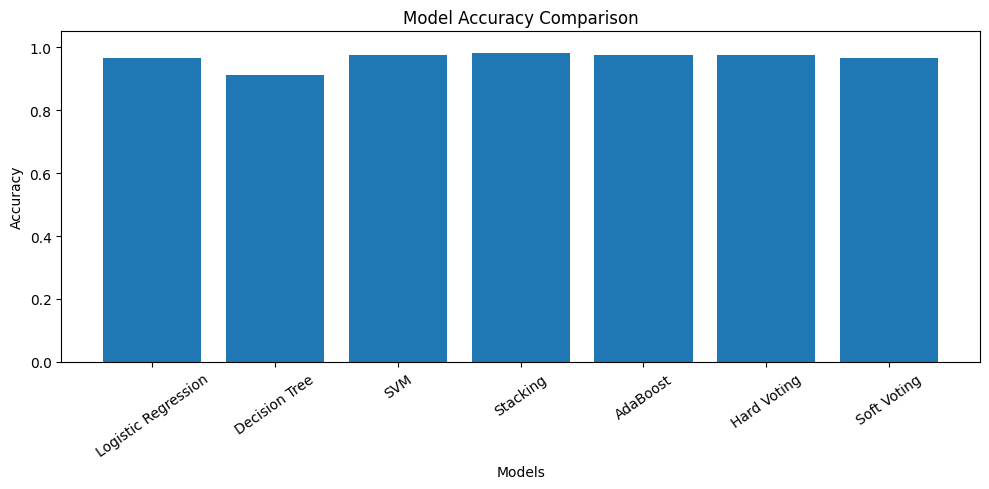

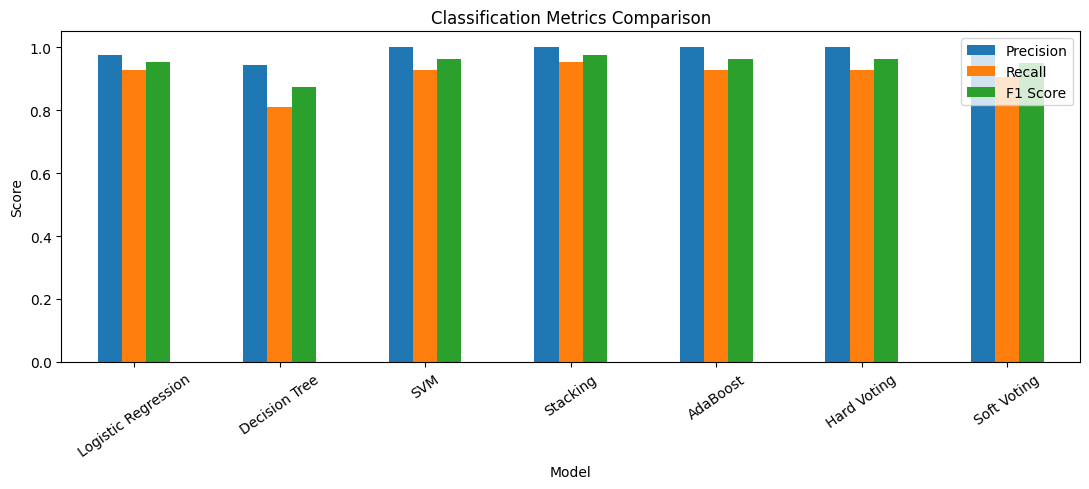

In [12]:

# Accuracy comparison
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['Accuracy']
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


# Precision, Recall and F1 comparison
results_df.set_index('Model')[
    ['Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(11, 5))

plt.title("Classification Metrics Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


# Step 10: Confusion Matrix of Best Model
For this experiment, select the model with the highest cross-validation recall. The test data is used only to evaluate its final performance.

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



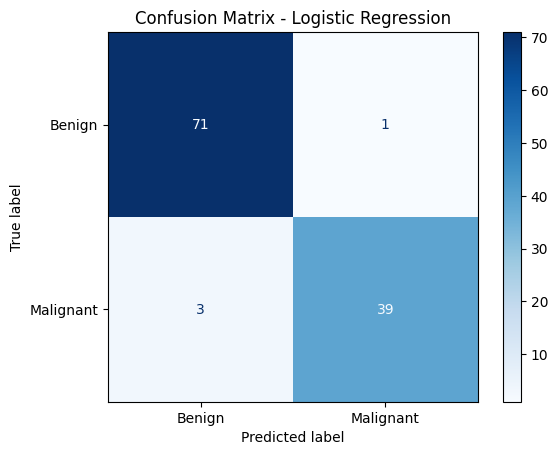

In [13]:

best_name = cv_df.loc[
    cv_df['Recall'].idxmax(), 'Model'
]

best_model = models[best_name]

best_pred = best_model.predict(X_test)

print("Best Model:", best_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    target_names=['Benign', 'Malignant']
))

cm = confusion_matrix(y_test, best_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Malignant']
)

display.plot(cmap='Blues')
plt.title("Confusion Matrix - " + best_name)
plt.show()


# 7. Output
The program generates the following outputs:
1. Dataset information and training/testing sample counts.
2. Performance of individual classifiers.
3. Stacking ensemble results.
4. AdaBoost ensemble results.
5. Hard and Soft Voting results.
6. Model comparison table.
7. Cross-validation results.
8. Accuracy and classification metric graphs.
9. Confusion matrix and classification report.
10. Best-performing model based on cross-validation recall.

# 8. Comparative Analysis
The implemented models are compared based on their classification performance.
- Logistic Regression provides a simple and interpretable classification approach.
- Decision Tree identifies patterns using decision rules but may overfit.
- SVM performs classification by finding an optimal decision boundary.
- Stacking combines different classifiers using a meta-classifier.
- AdaBoost improves weak learners by focusing on incorrectly classified samples.
- Hard Voting uses majority predictions from the base classifiers.
- Soft Voting combines predicted probabilities to make the final decision.
The best model is selected using cross-validation recall, with F1-score and ROC-AUC also considered to understand its overall performance.

# 9. Findings and Future Scope
Findings:
1. Ensemble learning provides a way to combine the strengths of multiple classifiers.
2. Stacking learns how different classifiers can work together.
3. AdaBoost focuses on improving classification errors.
4. Voting provides a simple method of combining model predictions.
5. The best-performing technique depends on the dataset and evaluation metrics.
Future Scope:
- Implement Random Forest and Gradient Boosting.
- Apply hyperparameter tuning using GridSearchCV.
- Perform feature selection.
- Experiment with different classification thresholds.
- Test the techniques on larger and different datasets.
- Evaluate fairness across different patient populations.
# 10. Ethical Considerations
Since the experiment uses a breast cancer dataset, responsible use of predictions is important.
- Patient data should remain private and secure.
- Training datasets should be checked for bias.
- False-negative predictions should receive special attention.
- Model predictions should be explainable.
- Machine learning models should not replace professional medical diagnosis.